In [1]:
%pip install pmdarima


   ---------------------------------------- 0.0/722.6 kB ? eta -:--:--
   ---- ----------------------------------- 81.9/722.6 kB 2.3 MB/s eta 0:00:01
   --------------------------------------  716.8/722.6 kB 11.4 MB/s eta 0:00:01
   ---------------------------------------- 722.6/722.6 kB 9.1 MB/s eta 0:00:00
   ---------------------------------------- 0.0/2.9 MB ? eta -:--:--
   ----------------------- ---------------- 1.7/2.9 MB 53.2 MB/s eta 0:00:01
   ---------------------------------------- 2.9/2.9 MB 46.1 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
%pip install yfinance


  Using cached beautifulsoup4-4.15.0-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/158.3 kB ? eta -:--:--
   ---------------------------------------- 158.3/158.3 kB 4.8 MB/s eta 0:00:00
Using cached beautifulsoup4-4.15.0-py3-none-any.whl (109 kB)
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ------------------------ --------------- 1.3/2.1 MB 42.0 MB/s eta 0:00:01
   ---------------------------------------- 2.1/2.1 MB 44.6 MB/s eta 0:00:00
   ---------------------------------------- 0.0/194.5 kB ? eta -:--:--
   --------------------------------------- 194.5/194.5 kB 12.3 MB/s eta 0:00:00
   ---------------------------------------- 0.0/219.6 kB ? eta -:--:--
   ---------------------------------------- 219.6/219.6 kB ? eta 0:00:00
   ---------------------------------------- 0.0/55.1 kB ? eta -:--:--
   ---------------------------------------- 55.1/55.1 kB ? eta 0:00:00
Note: you may need to restart the kernel to use updated p


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf,plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from pmdarima.arima import auto_arima
from sklearn.metrics import mean_squared_error
import yfinance as yf
from sklearn.model_selection import train_test_split

In [5]:
df=yf.download(
    "005930.KS",
    start="2024-01-01",
    end="2024-12-12",
)
df.head()

[*********************100%***********************]  1 of 1 completed

Price,Close,High,Low,Open,Volume
Ticker,005930.KS,005930.KS,005930.KS,005930.KS,005930.KS
Date,,,,,
2024-01-02,74734.500000,74922.275126,73420.074121,73420.074121,17142847
2024-01-03,72293.429688,73983.405966,72293.429688,73701.743253,21753644
2024-01-04,71917.882812,72575.095841,71448.444935,71448.444935,15324439
2024-01-05,71917.882812,72387.320690,71730.107662,72011.770388,11304316
2024-01-08,71823.984375,72762.859988,71730.096814,72293.422181,11088724


In [6]:
df_close=df["Close"]
df_close.head()

Ticker,005930.KS
Date,
2024-01-02,74734.500000
2024-01-03,72293.429688
2024-01-04,71917.882812
2024-01-05,71917.882812
2024-01-08,71823.984375


In [7]:
df=yf.download(
    "005930.KS",
    start="2026-01-01",
    end="2026-11-16",
)
df.head()

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,005930.KS,005930.KS,005930.KS,005930.KS,005930.KS
Date,,,,,
2026-01-02,125910.515625,125910.515625,117777.774149,117777.774149,30463279
2026-01-05,135317.062500,135806.986694,130907.744750,131887.593139,42863376
2026-01-06,136100.937500,136492.876845,130025.877655,132573.483396,45321341
2026-01-07,138158.609375,141490.093573,134827.125177,140608.230109,46317413
2026-01-08,136002.953125,141588.088808,135513.028942,135513.028942,41449329


In [9]:
df_close=df["Close"]
df_close.tail()

Ticker,005930.KS
Date,
2026-11-09,189900.0
2026-11-10,198900.0
2026-11-11,206000.0
2026-11-12,208000.0
2026-11-13,206000.0


In [10]:
if isinstance(df_close,pd.DataFrame):
    df_close = df_close.iloc[:,0]

df_close.head()

Date
2026-01-02    125910.515625
2026-01-05    135317.062500
2026-01-06    136100.937500
2026-01-07    138158.609375
2026-01-08    136002.953125
Name: 005930.KS, dtype: float64

In [11]:
df_close=df_close.dropna()

In [12]:
data=df_close.to_numpy()

In [13]:
train_size = int(len(data)*0.8)

train=data[:train_size]
test=data[train_size:]

In [23]:
test_index=df_close.index[train_size:]


In [ ]:
#p(20):과거 데이터 20개 시점의 값을 이용하여 현재 값을 예측하는 파라미터
#d(3): 시계열 데이터의 추세를 제거하고 정상성을 확보하기 위해 차분을 3번수행한다는 의미
#q(60): 과거 60개 시점의 예측 오차를 활용하는 파라미터(ma)
model=ARIMA(train,order=(20,3,60))
model_fitted=model.fit()

c:\Users\Win11Pro\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:989: EstimationWarning: Too few observations to estimate starting parameters for ARMA and trend. All parameters except for variances will be set to zeros.
  params_variance) = self._conditional_sum_squares(
c:\Users\Win11Pro\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [17]:
prediction=model_fitted.forecast(steps=len(test))


In [24]:
predictions=pd.Series(prediction,index=test_index)


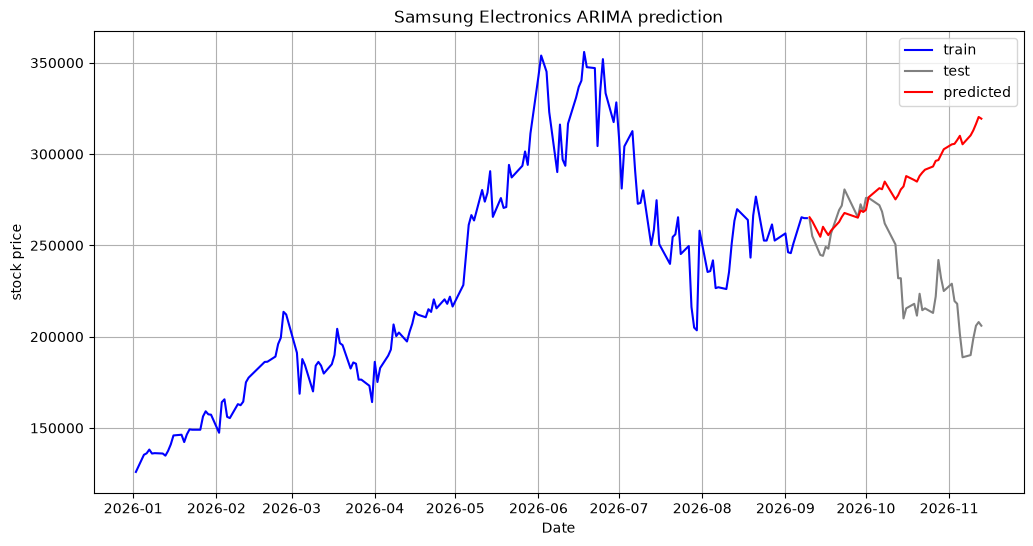

In [25]:
plt.figure(figsize=(12,6))
plt.plot(df_close.index[:train_size],train,label="train",color="blue")
plt.plot(test_index,test,label="test",color="gray")
plt.plot(test_index,predictions,label="predicted",color="red")
plt.title("Samsung Electronics ARIMA prediction")
plt.xlabel("Date")
plt.ylabel("stock price")
plt.legend()
plt.grid(True)
plt.show()